In [1]:
import numpy as np
from scipy.spatial.transform import Rotation as R
import sys
sys.path.append('/home/peter/Research/Tools')
from torque import eval_torque

from pyscf import gto

bas = 'stuttgartrsc'

molcoords = """
Cr1          1.130432197164135     0.000000000000000     0.000000000000000    ;
Cr2          -0.565216098582067    0.978983000000000     0.000000000000000    ;
Cr3          -0.565216098582067    -0.978983000000000    0.000000000000000    ;
"""

molS = gto.Mole()
molS.atom = molcoords
molS.spin=18 # ^ Spin
molS.basis = bas # ^ Basis
molS.ecp = bas
molS.max_memory = 50000
molS.build()

In [2]:
a = 0.11
n = 100
x = np.linspace(0, n, n+1)[1:]
y = np.linspace(0, n, n+1)
x, y = np.meshgrid(x, y)
x = x.ravel()
y = y.ravel()
x1 = - x * a + y * 0.5 * a
y1 = y * a * np.sqrt(3) * 0.5
z1 = np.zeros_like(x1)
coords = np.vstack([x1, y1, z1]).T
mask = np.linalg.norm(coords, axis=1) < 5
coords = coords[mask]
rm3d = R.from_rotvec(np.array([0.0, 0.0, np.pi*2/3])).as_matrix()
coords1 = (rm3d @ coords.T).T
coords2 = (rm3d @ rm3d @ coords.T).T
coords = np.vstack([coords, coords1, coords2])

In [3]:
B = np.load('B.npy').T[-len(coords):]

In [4]:
B_new = np.zeros_like(B)
for i in range(len(coords)):
    coord = coords[i]
    coord_r1 = (rm3d @ coord.T).T
    coord_r2 = (rm3d @ rm3d @ coord.T).T

    s1 = R.from_rotvec(np.array([0.0, 1.0, 0.0]) * np.pi).as_matrix()
    s1 = s1 @ (-np.eye(3))
    coord_r3 = (s1 @ coord.T).T

    s2 = R.from_rotvec(np.array([np.sqrt(3)/2, 0.5, 0.0]) * np.pi).as_matrix()
    s2 = s2 @ (-np.eye(3))
    coord_r4 = (s2 @ coord.T).T

    s3 = R.from_rotvec(np.array([np.sqrt(3)/2, -0.5, 0.0]) * np.pi).as_matrix()
    s3 = s3 @ (-np.eye(3))
    coord_r5 = (s3 @ coord.T).T

    where1 = np.where(np.all(np.isclose(coords, coord_r1), axis=1))
    where2 = np.where(np.all(np.isclose(coords, coord_r2), axis=1))
    where3 = np.where(np.all(np.isclose(coords, coord_r3), axis=1))
    where4 = np.where(np.all(np.isclose(coords, coord_r4), axis=1))
    where5 = np.where(np.all(np.isclose(coords, coord_r5), axis=1))

    B1 = (rm3d.T @ B[where1].T).T
    B2 = (rm3d.T @ rm3d.T @ B[where2].T).T
    B3 = (s1.T @ B[where3].T).T
    B4 = (s2.T @ B[where4].T).T
    B5 = (s3.T @ B[where5].T).T

    B_new[i] = (B1 + B2 + B3 + B4 + B5 + B[i]) / 6

In [5]:
sys.path.append('/home/peter/Research/Tools')
from torque import eval_m
B = B_new
M = eval_m(molS, np.load('dm.npy'), coords)
T = B[:, 1] * M[:, 0] - B[:, 0] * M[:, 1]

In [6]:
a = 0.11
n = 100
x = np.linspace(0, n, n+1)[1:]
y = np.linspace(0, n, n+1)
x, y = np.meshgrid(x, y)
x = x.ravel()
y = y.ravel()
x1 = - x * a + y * 0.5 * a
y1 = y * a * np.sqrt(3) * 0.5
z1 = np.zeros_like(x1)
coords = np.vstack([x1, y1, z1]).T
mask = np.linalg.norm(coords, axis=1) < 5
coords = coords[mask]
rm3d = R.from_rotvec(np.array([0.0, 0.0, np.pi*2/3])).as_matrix()
coords1 = (rm3d @ coords.T).T
coords2 = (rm3d @ rm3d @ coords.T).T
coords0 = np.vstack([coords, coords1, coords2])

a = 0.33
n = 100
x = np.linspace(0, n, n+1)[1:]
y = np.linspace(0, n, n+1)
x, y = np.meshgrid(x, y)
x = x.ravel()
y = y.ravel()
x1 = - x * a + y * 0.5 * a
y1 = y * a * np.sqrt(3) * 0.5
z1 = np.zeros_like(x1)
coords = np.vstack([x1, y1, z1]).T
mask = np.linalg.norm(coords, axis=1) < 5
coords = coords[mask]
rm3d = R.from_rotvec(np.array([0.0, 0.0, np.pi*2/3])).as_matrix()
coords1 = (rm3d @ coords.T).T
coords2 = (rm3d @ rm3d @ coords.T).T
coords = np.vstack([coords, coords1, coords2])

def fuzzy_row_match(A, B, tol=1e-8):
    mask = np.zeros(len(A), dtype=bool)
    for i, row in enumerate(A):
        diffs = np.abs(B - row)
        matches = np.all(diffs < tol, axis=1)
        if np.any(matches):
            mask[i] = True
    return mask

mask = fuzzy_row_match(coords0, coords, tol=1e-8)

coords = coords0[mask]
T = T[mask]

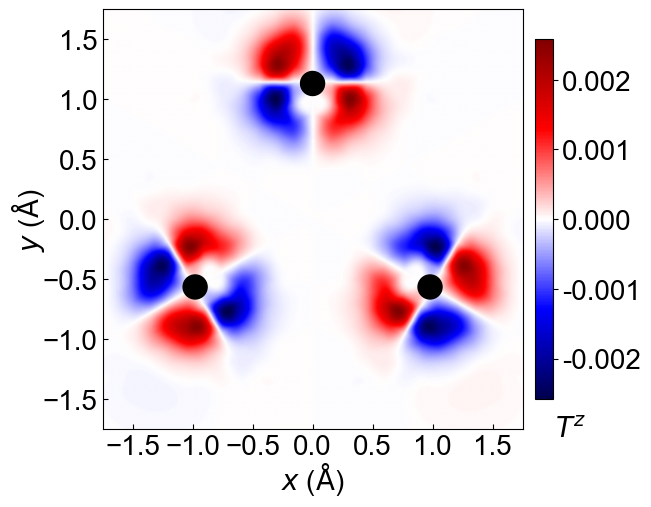

In [12]:
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

plt.rcParams['font.family'] = 'Arial'  # 设置字体类型
plt.rcParams['font.size'] = 20         # 设置全局字体大小

x = coords[:, 0]
y = coords[:, 1]

x_new = -y * 0.529177
y_new = x * 0.529177

# 假设你有原始散点数据：x_new, y_new, T[2]

# 设置规则网格
nx = ny = 500               # 这里可以改成 400/600/800/1000
x_lin = np.linspace(-1.75, 1.75, nx)
y_lin = np.linspace(-1.75, 1.75, ny)
Xi, Yi = np.meshgrid(x_lin, y_lin)

# 对原始数据进行高斯平滑
# T_smooth = gaussian_filter(T, sigma=0.)
T_smooth = T.copy()

Ti = griddata(
    points=np.column_stack((x_new, y_new)),
    values=T_smooth,  # Updated to use T_smooth instead of T[2]
    xi=(Xi, Yi),
    method='cubic'          # 'linear' 更快，'nearest' 最快；出版图建议 'cubic'
)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])
cax = fig.add_axes([0.87, 0.2, 0.03, 0.6])

im = ax.imshow(
    Ti,
    origin='lower',         # meshgrid + imshow 默认左下角是 (0,0)
    extent=[-1.75, 1.75, -1.75, 1.75],
    cmap='seismic',
    vmin=np.nanmin(Ti),   # 手动设 vmin/vmax 可保持同一配色
    vmax=np.nanmax(Ti),
    interpolation='bicubic'  # 让像素再平滑一点，可选 'nearest'
)
cbar = plt.colorbar(im, ax=ax, cax=cax)
cbar.ax.yaxis.set_major_formatter(plt.FormatStrFormatter('%.3f'))
# cbar.set_label('$|\mathbf{m}\\times \mathbf{B}_{\mathrm{xc}}|$ (a.u.)', fontsize=16)
label_text = '$T^z$'
label_y_position = -0.05 # 调整这个值来控制标签和Colorbar底部的距离
cbar.ax.text(2.0, label_y_position, label_text,
            transform=cbar.ax.transAxes, # 使用 cbar.ax 的坐标系
            rotation=0,                  # 水平文本
            ha='center',                 # 水平居中
            va='top',                    # 垂直对齐：文本顶部对齐 y 坐标
            fontsize=plt.rcParams['font.size']) # 确保字体大小一致

obstacles = np.array([(1.1304, 0.0), (-0.5652, 0.9789), (-0.5652, -0.9789)])
obstacles_rotated = np.column_stack((-obstacles[:,1], obstacles[:,0]))  # 逆时针旋转90度

for (ox, oy) in obstacles_rotated:
    circle = plt.Circle((ox, oy), 0.1, color='black')
    ax.add_patch(circle)

ax.set_aspect('equal')
ax.tick_params(axis='both', which='major', direction='in')
ax.set_xlim(-1.75, 1.75)
ax.set_ylim(-1.75, 1.75)
ax.set_xticks(np.arange(-1.5, 2, 0.5))
ax.set_yticks(np.arange(-1.5, 2, 0.5))
ax.set_xlabel('$x$ ($\mathrm{\AA}$)', labelpad=0.)
ax.set_ylabel('$y$ ($\mathrm{\AA}$)', labelpad=-3)

# fig.colorbar(im, ax=ax)
# plt.tight_layout()
# plt.show()
plt.savefig('Torque.png', dpi=600, bbox_inches='tight', pad_inches=0.05)